# 03. Modeling

02에서 입력을 **ΔQ 로그분산 하나**, 타깃을 **cycle_life**로 정했다. 이 노트북은 그 입력을 두고 후보 모델을 비교해 하나를 고른다. 이어서 Train으로만 학습한 그 모델을 Valid → Batch 2 → Batch 3 순서로 한 번씩 평가하고, 원논문 성능과의 차이를 해석한다.

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.linear_model import Ridge
from src.features import FEATURES, load
from src.train import CANDIDATES, TOLERANCE, compare_models, choose, cv_scores, evaluate, make_model, mape
pd.set_option("display.precision", 2)
COLORS = {"Batch 1": "#1A56DB", "Batch 2": "#EA7A1A", "Batch 3": "#8B5CF6"}
df = load()
train = df[df.role == "train"]

## 1. 후보 모델

| 순서 | 후보 | 왜 후보인가 |
|---|---|---|
| 0 | 중앙값 기준선 | 피처 없이 얻을 수 있는 오차. 이보다 나아야 의미가 있다 |
| 1 | **Ridge** | ΔQ와 수명이 거의 직선이다(01). 학습 수명 범위 밖으로도 예측할 수 있다 |
| 2 | ElasticNet | 원논문이 쓴 모델. 피처가 많을 때 자동으로 고르는 장점이 있다 |
| 3 | 얕은 Random Forest | 비선형 관계가 남아 있는지 확인하는 용도 |

01에서 테스트 셀 상당수가 학습 수명 범위 밖에 있음을 확인했다. 그래서 **학습 범위 밖을 예측할 수 있는가**가 후보 선택의 중요한 조건이다. 아래 그림은 Train 셀(점)로 학습한 Ridge와 RF에 ΔQ 값을 넓은 범위로 넣었을 때 내는 예측값(선)이다. 회색 점선은 Train 수명의 최솟값(599회)과 최댓값(1,227회)이다.

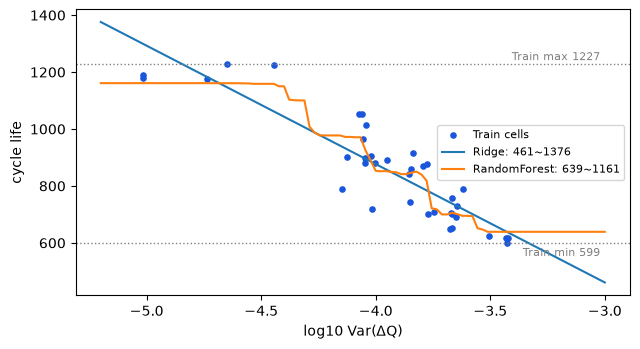

In [2]:
grid = pd.DataFrame({"dq_log_var": np.linspace(-5.2, -3.0, 100)})
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.scatter(train.dq_log_var, train.life, s=14, color=COLORS["Batch 1"], label="Train cells")
for name in ("Ridge", "RandomForest"):
    m = make_model(CANDIDATES[name][-1 if name == "RandomForest" else 0]).fit(train[FEATURES], train.life)
    p = m.predict(grid)
    ax.plot(grid.dq_log_var, p, label=f"{name}: {p.min():.0f}~{p.max():.0f}")
for y in (train.life.min(), train.life.max()):
    ax.axhline(y, color="gray", ls=":", lw=1)
ax.text(-3.02, train.life.max() + 15, f"Train max {train.life.max():.0f}", ha="right", fontsize=8, color="gray")
ax.text(-3.02, train.life.min() - 45, f"Train min {train.life.min():.0f}", ha="right", fontsize=8, color="gray")
ax.set(xlabel="log10 Var(ΔQ)", ylabel="cycle life"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**확인.** RF 선은 ΔQ가 아무리 커지거나 작아져도 두 점선 안(약 640~1,160회)에서 평평해진다. 트리는 학습 셀 수명의 평균만 낼 수 있어, Train보다 짧거나 긴 수명은 예측할 수 없다. Ridge 선은 직선을 따라 점선 밖으로 이어진다. → Ridge를 주 후보로 두고, RF는 비교용으로만 둔다는 설계가 맞다.

## 2. 선정 규칙

1. 각 후보는 작은 하이퍼파라미터 그리드에서 **Batch 1 Train 정책 단위 4-fold CV** 평균 MAPE가 가장 낮은 설정을 쓴다.
2. 기준선을 뺀 후보 중 최저 CV에서 **0.5%p 이내**인 후보가 여럿이면, 더 단순한 모델(Ridge → ElasticNet → RF)을 택한다. 02와 같은 이유다. 이보다 작은 차이는 셀 한두 개로 뒤집힌다.
3. Valid·Batch 2·Batch 3 점수는 선정에 쓰지 않는다.

In [3]:
best = compare_models(train, FEATURES)
chosen = choose(best)
show = best.drop(columns="estimator").copy()
show["selected"] = show.model == chosen.model
show

,model,params,cv_mape,cv_std,selected
0,Median,{},19.65,4.24,False
1,Ridge,{'alpha': 0.01},8.98,2.68,True
2,ElasticNet,"{'alpha': 0.001, 'l1_ratio': 0.8}",8.98,2.68,False
3,RandomForest,{'max_depth': 3},11.11,5.29,False


In [4]:
folds = pd.DataFrame({r.model: cv_scores(train, FEATURES, make_model(r.estimator)) for r in best.itertuples()},
                     index=[f"fold {i}" for i in range(4)]).T
folds

,fold 0,fold 1,fold 2,fold 3
Median,17.60,13.73,22.97,24.32
Ridge,7.96,7.85,13.53,6.59
ElasticNet,7.96,7.85,13.53,6.59
RandomForest,10.84,6.74,19.83,7.03


**결과 → 선택: Ridge (α=0.01).**
- Ridge와 ElasticNet은 8.98%로 같다. 입력이 하나라 L1 선택이 할 일이 없고, 두 모델이 같은 직선으로 수렴한다. 같은 점수에서는 더 단순한 Ridge를 택한다.
- 얕은 RF는 11.11%로 2%p 이상 나쁘고, 폴드 편차도 5.29%p로 가장 크다. 남은 비선형 신호는 보이지 않는다.
- 폴드 2(13.5%)가 가장 어렵다. 이 폴드에 Batch 1 최장수명 셀(1,227회)이 있고, 직선이 긴 수명 쪽 끝을 짧게 예측하기 때문이다.

## 3. 최종 성능

Train 37셀로 한 번 학습한 같은 모델로 평가한다.

In [5]:
table, pred, final = evaluate(df, make_model(chosen.estimator), FEATURES, chosen.cv_mape)
table.round(2)

,구분,MAPE (%),비고
0,Train (Batch 1 CV),8.98,"정책 단위 4-fold 평균, 37셀"
1,Valid (Batch 1 Hold-out),10.38,"학습에 없는 정책, 9셀"
2,Test (Batch 2),33.04,39셀
3,Gap (Train-Valid),1.40,(+) : 과적합 의심
4,Gap (Valid-Test),22.66,(+) : 배치간 일반화 저하 의심
5,Gap (Target-Test),23.94,Target : 원논문 9.1%
6,Test (Batch 3),12.85,44셀
7,Gap (Batch2-Batch3),20.19,Test 성능 간 비교
8,Gap (Target-Test),3.75,"Batch 3 기준, 원논문 성능 비교"
9,"Test (Batch 3, 노이즈 4셀 제외)",12.87,"40셀, 원논문 제거 채널 제외"


### Gap 해석

- **Gap (Train-Valid) = +1.40%p → 과적합 징후는 작다.** 처음 보는 정책 5개(9셀)에서도 CV와 비슷한 오차가 나온다. 피처가 하나라 학습 데이터에 맞춰 외울 여지가 적다.
- **Gap (Valid-Test) = +22.66%p → 배치 간 일반화가 크게 저하된다.** 같은 배치(Batch 1) 안에서는 처음 보는 충전 정책에도 일반화되지만, 다른 시기에 측정한 배치로 옮기면 오차가 3배 이상이 된다. 원인은 아래 4절에서 셀 단위로 본다.
- **Gap (Target-Test) = +23.94%p → 원논문 9.1%와 크게 차이 난다.** 이 차이의 대부분은 모델이 아니라 **데이터 분할 방식**에서 온다. 5절에서 근거를 보인다.

## 4. Batch 2 오차 분석

In [6]:
test = pred[pred.role == "test"].assign(residual=lambda d: d.pred - d.life)
display(test.groupby("structure").agg(cells=("cell", "size"), life_median=("life", "median"), pred_median=("pred", "median"),
                                      residual_median=("residual", "median"), mape=("ape", "mean")))
display(test.nlargest(6, "ape")[["cell", "policy", "structure", "life", "pred", "ape"]])

,cells,life_median,pred_median,residual_median,mape
structure,,,,,
newstructure,9,904.0,973.14,15.39,14.10
original,30,451.0,650.36,187.07,38.73


,cell,policy,structure,life,pred,ape
52,2-07,3.6C(9%)-5C,original,393.0,681.33,73.37
61,2-16,3.6C(9%)-5C,original,396.0,675.60,70.60
64,2-19,5.2C(50%)-4.25C,original,449.0,755.06,68.16
48,2-03,5.2C(50%)-4.25C,original,424.0,652.30,53.85
73,2-30,5.2C(58%)-4C,original,452.0,672.27,48.73
65,2-20,6C(60%)-3C,original,392.0,582.31,48.55


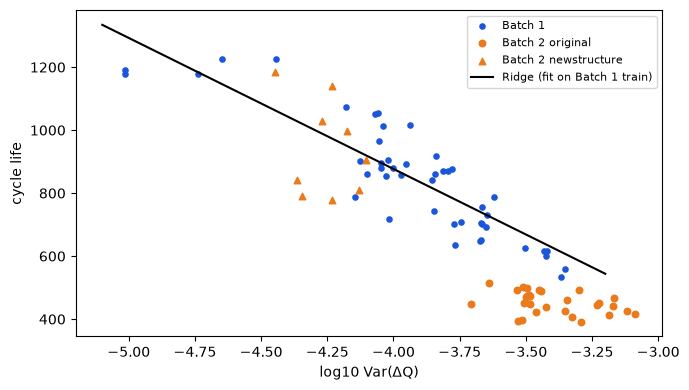

Batch 1            slope    -433  예측선 대비 중앙 잔차    -12
Batch 2 original   slope     -86  예측선 대비 중앙 잔차   -187


In [7]:
ridge = make_model(chosen.estimator).fit(train[FEATURES], train.life)
x = pd.DataFrame({"dq_log_var": np.linspace(-5.1, -3.2, 50)})
fig, ax = plt.subplots(figsize=(7, 4))
b1 = df[df.batch == "Batch 1"]
ax.scatter(b1.dq_log_var, b1.life, s=14, color=COLORS["Batch 1"], label="Batch 1")
for s, mk in (("original", "o"), ("newstructure", "^")):
    g = test[test.structure == s]
    ax.scatter(g.dq_log_var, g.life, s=22, marker=mk, color=COLORS["Batch 2"], label=f"Batch 2 {s}")
ax.plot(x.dq_log_var, ridge.predict(x), color="black", label="Ridge (fit on Batch 1 train)")
ax.set(xlabel="log10 Var(ΔQ)", ylabel="cycle life"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
for name, g in [("Batch 1", b1), ("Batch 2 original", test[test.structure == "original"])]:
    slope, intercept = np.polyfit(g.dq_log_var, g.life, 1)
    print(f"{name:18s} slope {slope:7.0f}  예측선 대비 중앙 잔차 {np.median(g.life - ridge.predict(g[FEATURES])):6.0f}")

In [8]:
tr_max = train.dq_log_var.max()
orig = test[test.structure == "original"].assign(in_train_dq_range=lambda d: d.dq_log_var <= tr_max)
display(orig.groupby("in_train_dq_range").agg(cells=("cell", "size"), mape=("ape", "mean"), residual_median=("residual", "median")))
same = ["6C(60%)-3C", "4.8C(80%)-4.8C"]  # Batch 1과 Batch 2 기존 절차에 모두 있는 정책
display(df[df.policy.isin(same) & df.batch.isin(["Batch 1", "Batch 2"])]
        .groupby(["policy", "batch"]).agg(cells=("cell", "size"), life_mean=("life", "mean"), dq_mean=("dq_log_var", "mean")))

,cells,mape,residual_median
in_train_dq_range,,,
False,12,28.40,108.41
True,18,45.61,196.34


cells  life_mean  dq_mean
policy         batch                             
4.8C(80%)-4.8C Batch 1      2      753.0    -3.79
               Batch 2      5      483.6    -3.50
6C(60%)-3C     Batch 1      2      744.0    -3.66
               Batch 2      2      400.0    -3.31

**관찰.**
- 오차는 **기존 절차 30셀**에 몰려 있다(MAPE 38.7%). 이 셀들은 모두 실제보다 길게 예측된다(중앙 잔차 약 +190회). `newstructure` 9셀은 14.1%로 Batch 3과 비슷한 수준이다.
- 기존 절차 셀의 ΔQ는 Batch 1 범위 중 큰 쪽(단수명 쪽) 끝에 몰려 있고, 12셀은 Train 범위를 넘는다. 그런데 **ΔQ가 범위 안에 있는 18셀이 오히려 더 크게 틀린다**(45.6% vs 28.4%). 피처 외삽이 아니라 **같은 ΔQ에 대응하는 수명 자체가 내려가 있다**(절편 이동).
- **같은 충전 정책으로 비교하면 더 분명하다.** 6C(60%)-3C 정책은 Batch 1에서 평균 744회인데, Batch 2 기존 절차에서는 400회다. 4.8C(80%)-4.8C도 753회 → 484회다. 정책이 같은데 수명이 36~46% 짧다. ΔQ도 커졌지만(초기 열화가 더 큼) 수명은 그보다 더 많이 줄었다.

**원인 가설.** 01에서 사이클 번호 어긋남은 원인이 아님을 확인했다. 같은 정책에서도 수명이 크게 다르므로 충전 정책 차이도 주원인이 아니다. 남는 후보는 **배치 수준의 차이**다. 수개월의 측정 시기 차이 동안의 셀 상태 변화와, 휴지 시간·충전 시작 상태 같은 실험 조건 차이가 여기에 해당한다. 이 데이터만으로는 둘을 분리할 수 없다. 분명한 것은 학습 배치가 하나뿐이면 이런 배치 수준의 이동을 모델이 학습할 방법이 없다는 점이다.

## 5. 원논문과의 차이

| | 원논문 | 이 프로젝트 |
|---|---|---|
| 학습 | Batch 1·2를 섞어 41셀 | Batch 1의 37셀만 |
| 1차 테스트 | 같은 Batch 1·2의 나머지 43셀 | **처음 보는 배치** Batch 2의 39셀 |
| 2차 테스트 | Batch 3의 40셀 | Batch 3의 44셀 |
| 피처 | 단일 ΔQ 모델 / 최대 9개(최고 성능 9.1%) | ΔQ 1개 |
| 단일 ΔQ 모델 성능 | 1차 약 15%, 2차 약 11% | Batch 2 33.0%, Batch 3 12.9% |

원논문은 1차 테스트 셀과 같은 배치의 셀로 학습했다. 이 프로젝트의 Batch 2는 학습에 한 번도 등장하지 않은 배치다. 같은 피처·같은 모델에서 분할 방식만 원논문처럼 바꾸면 어떻게 되는지 확인했다. 이 결과는 **진단용**이며 모델 선정에는 쓰지 않는다.

In [9]:
pool = df[df.batch.isin(["Batch 1", "Batch 2"])].sort_values("life").reset_index(drop=True)
b3 = df[df.batch == "Batch 3"]
rows = []
for start in (0, 1):  # 수명 순으로 번갈아 학습/테스트 (두 가지 경우)
    fit, check = pool.iloc[start::2], pool.iloc[1 - start::2]
    m = make_model(Ridge(alpha=0.01)).fit(fit[FEATURES], fit.life)
    rows.append({"split": f"interleave {start}", "train": len(fit), "test": len(check),
                 "test MAPE (B1+B2 mixed)": mape(check.life, m.predict(check[FEATURES])),
                 "Batch 3 MAPE": mape(b3.life, m.predict(b3[FEATURES]))})
pd.DataFrame(rows)

,split,train,test,test MAPE (B1+B2 mixed),Batch 3 MAPE
0,interleave 0,43,42,14.66,13.17
1,interleave 1,42,43,12.73,12.22


**결과.** 같은 ΔQ 하나와 같은 Ridge로, 분할만 원논문처럼 Batch 1·2를 섞으면 테스트 MAPE가 **12.7~14.7%**가 된다. 원논문의 단일 ΔQ 모델 1차 테스트(약 15%)와 같은 수준이고, Batch 3(12.2~13.2%)도 원논문 2차 테스트(약 11%)에 가깝다.

**Gap (Target-Test) +23.9%p의 해석.**
- 약 **6%p**(9.1% → 약 15%)는 피처 수 차이다. 원논문 최고 성능은 여러 피처를 쓴 모델이고, 단일 ΔQ 모델은 약 15%다.
- 나머지 약 **18%p**(약 15% → 33%)는 **처음 보는 배치로 일반화하는 비용**이다. Batch 2를 학습에 일부 섞기만 해도 사라지는 오차다.

Batch 1만으로 학습하라는 과제 조건 아래에서는 9.1%를 재현할 수 없다. 이 Gap은 배치 이동에 대한 강건성이 실제 배포의 핵심 문제라는 것을 보여준다.

## 6. Batch 3 추가 평가

In [10]:
b3p = pred[pred.role == "batch3"].assign(residual=lambda d: d.pred - d.life,
                                         over_train_max=lambda d: d.life > train.life.max())
display(b3p.groupby("over_train_max").agg(cells=("cell", "size"), mape=("ape", "mean"), residual_median=("residual", "median")))
display(b3p.nlargest(6, "ape")[["cell", "policy", "life", "pred", "ape", "noisy"]])
print("노이즈 채널 4셀:", b3p[b3p.noisy][["cell", "life", "pred", "ape"]].round(1).to_string(index=False))

,cells,mape,residual_median
over_train_max,,,
False,35,9.24,-16.52
True,9,26.89,-472.35


,cell,policy,life,pred,ape,noisy
121,3-39,5C(67%)-4C-newstructure,1935.0,1019.05,47.34,False
92,3-08,4.8C(80%)-4.8C-newstructure,1836.0,1080.06,41.17,False
128,3-46,4.8C(80%)-4.8C-newstructure,1801.0,1093.42,39.29,False
125,3-43,4.8C(80%)-4.8C-newstructure,1642.0,1020.78,37.83,True
101,3-17,4.8C(80%)-4.8C-newstructure,1638.0,1165.65,28.84,False
123,3-41,5.6C(19%)-4.6C-newstructure,796.0,999.53,25.57,False


노이즈 채널 4셀: cell   life   pred  ape
3-03 1267.0 1200.9  5.2
3-38 1390.0 1333.8  4.0
3-43 1642.0 1020.8 37.8
3-44 1046.0 1008.5  3.6


**관찰.**
- Batch 3 전체 MAPE는 **12.85%**로 Batch 2보다 20.19%p 낮다. Batch 3은 전부 `newstructure`이고, Batch 2의 `newstructure` 9셀 오차(14.1%)와 비슷하다. **Gap (Batch2-Batch3)의 대부분은 Batch 2 기존 절차 셀의 절편 이동에서 온다.** ΔQ 피처가 Batch 1에만 과적합됐다고 보기는 어렵다. 같은 피처가 원논문 분할에서도, Batch 3에서도 비슷한 오차를 낸다.
- Batch 3의 오차는 Batch 2와 **반대 방향**이다. Train 최대 수명 1,227회를 넘는 장수명 셀을 짧게 예측한다(3-39: 1,935회 → 약 1,020회). Batch 1 직선의 기울기를 그 범위 밖까지 그대로 연장한 결과다.
- 원논문이 제거한 노이즈 채널 4셀을 빼도 MAPE는 12.87%로 거의 같다. 이 모델에서는 노이즈 셀이 결과를 좌우하지 않는다.
- **Train 수명 범위 안의 35셀만 보면 MAPE는 9.24%로 원논문 9.1%와 같은 수준이다.** 오차의 대부분은 범위 밖 9셀(26.9%)에서 나온다. Gap (Target-Test, Batch 3) +3.75%p는 피처의 한계라기보다 학습 수명 범위의 한계다.

## 7. 오류 분석

| 크게 틀린 셀 | 공통점 | 방향 |
|---|---|---|
| Batch 2 기존 절차 (2-07, 2-16, 2-19 …) | 같은 ΔQ·같은 정책인데 수명이 짧음(배치 이동) | **과대예측** |
| Batch 3 장수명 (3-39, 3-08, 3-46 …) | Train 최대 수명 1,227회를 넘는 셀 | **과소예측** |

공통점은 **학습 배치가 덮지 못한 영역**이라는 것이다. 하나는 다른 배치·절차이고, 다른 하나는 더 긴 수명대다. 개선 방향은 아래와 같다.
1. **학습 배치를 늘린다.** 원논문 분할 재현에서 보았듯, 여러 시기·절차의 셀을 섞어 학습하는 것이 가장 큰 개선이다.
2. **새 배치에 소수 셀로 보정한다.** 오차가 기울기보다 절편 이동에 가깝다. 새 배치에서 수명이 확정된 셀 몇 개로 절편만 다시 맞추는 방식을 검토할 수 있다.
3. **범위 이탈을 경고한다.** ΔQ나 정책이 학습 범위를 벗어나면 예측과 함께 신뢰도 경고를 낸다.

## 모델 저장과 재사용

최종 모델은 `results/model.joblib`에 저장한다. 새 셀은 100회까지 측정한 뒤 ΔQ 로그분산만 계산해 넣으면 수명이 나온다(`python -m src.predict new_cells.csv`). 아래에서 저장한 모델을 다시 불러, 방금 평가한 예측과 같은 값이 나오는지 확인한다.

In [11]:
from src.train import main
from src.predict import predict
main()  # results/model_performance.csv, predictions.csv, model.joblib 저장

reloaded = predict(pred)
assert np.allclose(reloaded, pred.pred)
ridge_step = final.named_steps["ridge"]; scaler = final.named_steps["standardscaler"]
slope = ridge_step.coef_[0] / scaler.scale_[0]
print(f"불러온 모델 예측 일치: {len(pred)}셀")
print(f"최종 모델 식: cycle_life = {slope:.1f} × ΔQ 로그분산 {ridge_step.intercept_ - slope * scaler.mean_[0]:+.1f}")

       model                            params  cv_mape  cv_std
      Median                                {}    19.65    4.24
       Ridge                   {'alpha': 0.01}     8.98    2.68
  ElasticNet {'alpha': 0.001, 'l1_ratio': 0.8}     8.98    2.68
RandomForest                  {'max_depth': 3}    11.11    5.29
chosen: Ridge {'alpha': 0.01}
                       구분  MAPE (%)                    비고
       Train (Batch 1 CV)      8.98  정책 단위 4-fold 평균, 37셀
 Valid (Batch 1 Hold-out)     10.38         학습에 없는 정책, 9셀
           Test (Batch 2)     33.04                   39셀
        Gap (Train-Valid)      1.40          (+) : 과적합 의심
         Gap (Valid-Test)     22.66   (+) : 배치간 일반화 저하 의심
        Gap (Target-Test)     23.94     Target : 원논문 9.1%
           Test (Batch 3)     12.85                   44셀
      Gap (Batch2-Batch3)     20.19          Test 성능 간 비교
        Gap (Target-Test)      3.75 Batch 3 기준, 원논문 성능 비교
Test (Batch 3, 노이즈 4셀 제외)     12.87     40셀, 원논문 제거 채널 제외
불러온 모델 예측 일치

## 정리

- **모델은 Ridge, 선택은 쉬웠음**
  - 입력이 하나라 ElasticNet은 Ridge와 같은 직선이 됨(8.98% 동일) → 단순한 쪽
  - RF는 11.11%로 나쁘고, 학습 수명 범위 밖을 아예 예측하지 못함
- **같은 배치 안에서는 잘 맞고, 배치를 넘으면 무너짐**
  - CV 8.98% → Valid 10.38%: 처음 보는 정책에도 버팀
  - Batch 2 33.04%: 오차가 3배
- **Batch 2 오차는 피처 문제가 아니라 배치 이동**
  - 기존 절차 30셀이 모두 길게 예측됨(중앙 +190회)
  - ΔQ가 학습 범위 안에 있는 셀이 오히려 더 크게 틀림
  - 같은 충전 정책인데도 Batch 2 수명이 36~46% 짧음 → 같은 ΔQ에 대응하는 수명 자체가 내려가 있음
- **논문과의 차이는 대부분 분할 방식에서 옴**
  - 같은 피처·같은 모델로 논문처럼 Batch 1·2를 섞어 나누면 12.7~14.7% → 논문의 ΔQ 단일 모델(약 15%)과 같은 수준
  - Gap +23.9%p ≈ 피처 수 차이 약 6%p + 처음 보는 배치 비용 약 18%p
- **Batch 3은 범위 안에서는 논문 수준**
  - 전체 12.85%, 학습 수명 범위 안 35셀은 9.24%
  - 오차는 1,227회를 넘는 장수명 셀에서 나옴(과소예측). 노이즈 4셀은 결과에 영향 없음
- **다음에 한다면**
  - 여러 시기·절차의 배치를 섞어 학습
  - 새 배치에서 수명이 확정된 셀 몇 개로 절편만 다시 보정
  - ΔQ·수명이 학습 범위를 벗어나면 예측과 함께 경고